In [1]:
import json
import shutil
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

THU_MUC_GOC = Path("..").resolve()
THU_MUC_DAC_TRUNG = THU_MUC_GOC / "data" / "features"
THU_MUC_MODEL = THU_MUC_GOC / "model"
THU_MUC_REPORT = THU_MUC_GOC / "report"

X_test = np.load(THU_MUC_DAC_TRUNG / "X_test.npy")
y_test = np.load(THU_MUC_DAC_TRUNG / "y_test.npy")

with open(THU_MUC_MODEL / "labels.json", "r", encoding="utf-8") as f:
    labels_map = json.load(f)

ten_cac_lop = [labels_map[str(i)] for i in range(len(labels_map))]

cau_hinh_mo_hinh = {
    "KNN": ("knn_model.pkl", "cv_knn.json"),
    "RandomForest": ("rf_model.pkl", "cv_rf.json"),
    "SVM": ("svm_model.pkl", "cv_svm.json"),
    "LogisticRegression":("lr_model.pkl", "cv_lr.json")
}

mo_hinh = {}
du_lieu_cv = {}

for ten, (file_pkl, file_json) in cau_hinh_mo_hinh.items():
    mo_hinh[ten] = joblib.load(THU_MUC_MODEL / file_pkl)
    with open(THU_MUC_REPORT / file_json, "r", encoding="utf-8") as f:
        du_lieu_cv[ten] = json.load(f)

print(f"Đã nạp X_test: {X_test.shape} | Các lớp: {ten_cac_lop}")
print("Đã nạp đủ 4 mô hình:", list(mo_hinh.keys()))

Đã nạp X_test: (3222, 1280) | Các lớp: ['Huu_Co', 'Tai_Che', 'Vo_Co']
Đã nạp đủ 4 mô hình: ['KNN', 'RandomForest', 'SVM', 'LogisticRegression']


In [2]:
ket_qua_test = []
du_doan_dict = {}

for ten, model in mo_hinh.items():
    file_pkl = THU_MUC_MODEL / cau_hinh_mo_hinh[ten][0]
    dung_luong_mb = file_pkl.stat().st_size / (1024 * 1024)

    bat_dau = time.perf_counter()
    y_pred = model.predict(X_test)
    thoi_gian_du_doan = time.perf_counter() - bat_dau

    du_doan_dict[ten] = y_pred

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    prec_macro = precision_score(y_test, y_pred, average="macro")
    rec_macro = recall_score(y_test, y_pred, average="macro")
    ms_moi_anh = (thoi_gian_du_doan / len(X_test)) * 1000

    ket_qua_test.append({
        "Model": ten,
        "CV_F1_Macro": du_lieu_cv[ten]["cv_f1_macro"],
        "Test_Accuracy": round(acc, 4),
        "Test_F1_Macro": round(f1_macro, 4),
        "Test_Precision": round(prec_macro, 4),
        "Test_Recall": round(rec_macro, 4),
        "Infer_ms_per_img": round(ms_moi_anh, 3),
        "Model_Size_MB": round(dung_luong_mb, 2),
        "Train_Time_s": du_lieu_cv[ten]["train_time_sec"],
    })

    print("=" * 60)
    print(f"BÁO CÁO CHI TIẾT TRÊN TẬP TEST — {ten}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=ten_cac_lop, digits=4))

bang_so_sanh = pd.DataFrame(ket_qua_test).sort_values(by="Test_F1_Macro", ascending=False)
bang_so_sanh.to_csv(THU_MUC_REPORT / "bang_so_sanh_test.csv", index=False, encoding="utf-8-sig")
display(bang_so_sanh)

BÁO CÁO CHI TIẾT TRÊN TẬP TEST — KNN
              precision    recall  f1-score   support

      Huu_Co     0.9819    0.9538    0.9677       910
     Tai_Che     0.9599    0.9729    0.9663      1402
       Vo_Co     0.9607    0.9681    0.9644       910

    accuracy                         0.9662      3222
   macro avg     0.9675    0.9650    0.9661      3222
weighted avg     0.9663    0.9662    0.9662      3222

BÁO CÁO CHI TIẾT TRÊN TẬP TEST — RandomForest
              precision    recall  f1-score   support

      Huu_Co     0.9619    0.9440    0.9529       910
     Tai_Che     0.9225    0.9601    0.9409      1402
       Vo_Co     0.9506    0.9088    0.9292       910

    accuracy                         0.9410      3222
   macro avg     0.9450    0.9376    0.9410      3222
weighted avg     0.9416    0.9410    0.9410      3222

BÁO CÁO CHI TIẾT TRÊN TẬP TEST — SVM
              precision    recall  f1-score   support

      Huu_Co     0.9767    0.9670    0.9718       910
     Tai_

,Model,CV_F1_Macro,Test_Accuracy,Test_F1_Macro,Test_Precision,Test_Recall,Infer_ms_per_img,Model_Size_MB,Train_Time_s
2,SVM,0.9657,0.9677,0.9680,0.9691,0.9669,6.552,42.39,599.2
0,KNN,0.9643,0.9662,0.9661,0.9675,0.9650,0.945,63.06,58.5
3,LogisticRegression,0.9513,0.9550,0.9551,0.9561,0.9543,0.007,0.05,78.1
1,RandomForest,0.9396,0.9410,0.9410,0.9450,0.9376,0.084,48.42,210.1


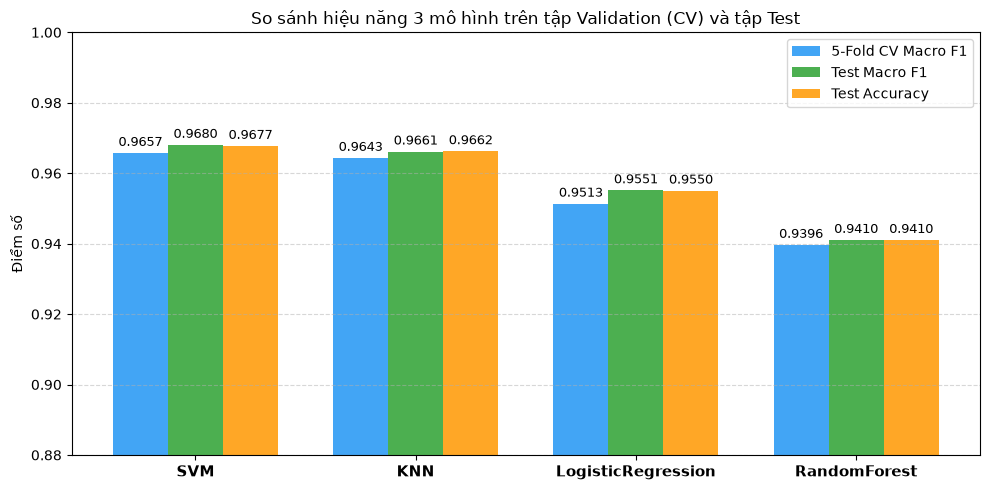

In [ ]:
x = np.arange(len(bang_so_sanh))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - width, bang_so_sanh["CV_F1_Macro"], width, label="5-Fold CV Macro F1", color="#42A5F5")
b2 = ax.bar(x, bang_so_sanh["Test_F1_Macro"], width, label="Test Macro F1", color="#4CAF50")
b3 = ax.bar(x + width, bang_so_sanh["Test_Accuracy"], width, label="Test Accuracy", color="#FFA726")

ax.set_ylim(0.88, 1.0)
ax.set_xticks(x)
ax.set_xticklabels(bang_so_sanh["Model"], fontsize=11, fontweight="bold")
ax.set_ylabel("Điểm số")
ax.set_title("So sánh hiệu năng 4 mô hình trên tập Validation (CV) và tập Test")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bars in (b1, b2, b3):
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig(THU_MUC_REPORT / "so_sanh_mo_hinh.png", dpi=150)
plt.show()

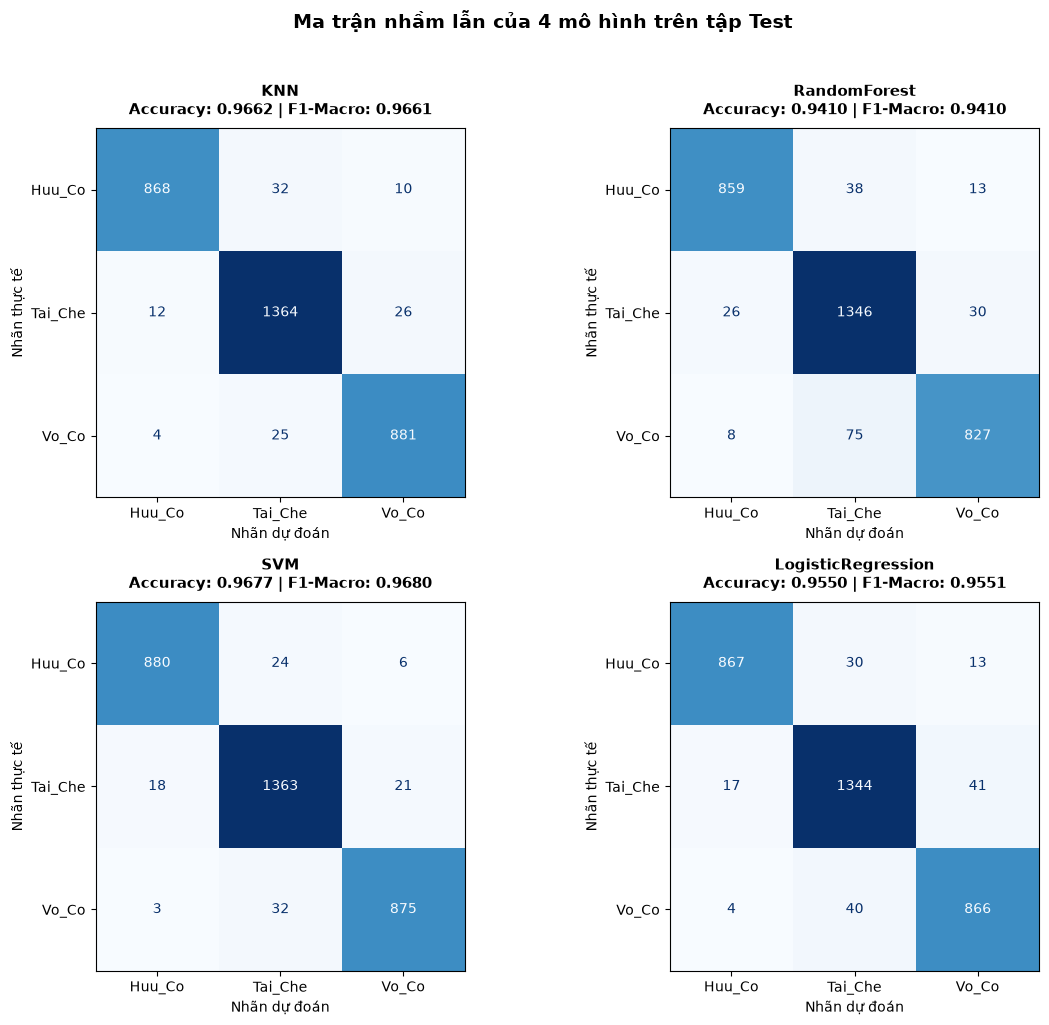

Đã lưu ảnh thành công tại: C:\Users\Nguyen Vu Thuan\Documents\ML_bao_cao\report\confusion_matrix_4_mo_hinh.png


In [5]:
THU_MUC_REPORT.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, (ten, model) in zip(axes, mo_hinh.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="macro")

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=ten_cac_lop)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

    ax.set_title(
        f"{ten}\nAccuracy: {acc:.4f} | F1-Macro: {f1:.4f}",
        fontsize=11,
        fontweight="bold",
        pad=10,
    )
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")

fig.suptitle(
    "Ma trận nhầm lẫn của 4 mô hình trên tập Test",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()

duong_dan_luu = THU_MUC_REPORT / "confusion_matrix_4_mo_hinh.png"
plt.savefig(duong_dan_luu, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Đã lưu ảnh thành công tại: {duong_dan_luu}")

In [4]:
dong_tot_nhat = bang_so_sanh.iloc[0]
ten_model_tot_nhat = dong_tot_nhat["Model"]
file_nguon = THU_MUC_MODEL / cau_hinh_mo_hinh[ten_model_tot_nhat][0]
file_dich = THU_MUC_MODEL / "model_tot_nhat.pkl"

shutil.copy2(file_nguon, file_dich)
thong_tin_best = {
    "model_duoc_chon": ten_model_tot_nhat,
    "nguon_model": file_nguon.name,
    "best_params": du_lieu_cv[ten_model_tot_nhat]["best_params"],
    "cv_f1_macro": float(dong_tot_nhat["CV_F1_Macro"]),
    "test_f1_macro": float(dong_tot_nhat["Test_F1_Macro"]),
    "test_accuracy": float(dong_tot_nhat["Test_Accuracy"]),
    "infer_ms_per_img": float(dong_tot_nhat["Infer_ms_per_img"]),
    "model_size_mb": float(dong_tot_nhat["Model_Size_MB"]),
    "labels": labels_map,
}

with open(THU_MUC_MODEL / "model_tot_nhat.json", "w", encoding="utf-8") as f:
    json.dump(thong_tin_best, f, ensure_ascii=False, indent=2)